# 🔍 DGNet: Deep Gradient Network — Block-by-Block Feature Map Visualizer
### Comprehensive Step-by-Step Visualization of Every Architecture Block

This notebook provides an in-depth, layer-by-layer visual tour of **DGNet** (*Deep Gradient Network for Camouflaged Object Detection*). When an image passes through DGNet, each component extracts, transforms, or fuses specific cues:

```
                          ┌───────────────────────────┐
                          │        Input Image        │
                          │     (384 x 384 x 3)       │
                          └─────────────┬─────────────┘
                                        │
           ┌────────────────────────────┴────────────────────────────┐
           ▼                                                         ▼
┌──────────────────────────────────────┐  ┌──────────────────────────────────────┐
│ Stream 1: Texture / Gradient Encoder │  │ Stream 2: Context Semantic Encoder   │
│  - 3-Stage ConvBR (Stride 2, 2, 2)   │  │  - Backbone (MobileNetV3-Large)      │
│  - pg: Edge Pred Logits (48x48x1)    │  │    Multi-Scale Strides 8, 16, 32    │
│  - xg: Gradient Features (48x48x32)  │  │    [x3: 48x48, x4: 24x24, x5: 12x12] │
└──────────────────┬───────────────────┘  │  - DR3/DR4/DR5 + CBAM (Reduce 64ch)  │
                   │                      │    [xr3: 48x48, xr4: 24x24, xr5: 12x12│
                   │                      └──────────────────┬───────────────────┘
                   │                                         │
                   └────────────────────┬────────────────────┘
                                        ▼
                  ┌──────────────────────────────────────────┐
                  │    Gradient-Induced Transition (GIT)     │
                  │ - Feature Interleaving (M = 8)           │
                  │ - Soft Grouping Strategy (N = [4, 8, 16])│
                  │ [zt3: 48x48x64, zt4: 24x24x64, zt5: 12x12│
                  └─────────────────────┬────────────────────┘
                                        ▼
                  ┌──────────────────────────────────────────┐
                  │   Neighbor Connection Decoder (NCD)      │
                  │ - Multiplicative Fusion                  │
                  │ - Cross-Scale Concatenation              │
                  │ - Deep Supervision                      │
                  │ [pc5: 12x12x1, pc4: 24x24x1, pc: 48x48x1]│
                  └─────────────────────┬────────────────────┘
                                        ▼
                  ┌──────────────────────────────────────────┐
                  │      Full-Resolution Output (384x384)    │
                  │ - Predicted Edge Map: Sigmoid(Bilinear(pg))
                  │ - Final Camouflage Mask: Sigmoid(Bilinear(pc))
                  └──────────────────────────────────────────┘
```

Every section displays the **block name**, **mathematical role**, **output tensor shapes**, and **visual feature activation maps**.


## 1. Environment Setup & Imports
Import TensorFlow, OpenCV, Matplotlib, and project components.


In [1]:
import os
import sys
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import tensorflow as tf

# Configure project root path
project_root = Path("..").resolve() if Path("..").resolve().joinpath("src").exists() else Path(".").resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.models.dgnet import build_dgnet_model, DGNet

# Set visual aesthetic styling
plt.rcParams['figure.facecolor'] = '#181824'
plt.rcParams['axes.facecolor'] = '#1f1f2e'
plt.rcParams['text.color'] = '#e0e0e0'
plt.rcParams['axes.labelcolor'] = '#e0e0e0'
plt.rcParams['xtick.color'] = '#a0a0a0'
plt.rcParams['ytick.color'] = '#a0a0a0'
plt.rcParams['axes.edgecolor'] = '#3a3a4c'
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

print(f"TensorFlow Version: {tf.__version__}")
print(f"GPU Available: {bool(tf.config.list_physical_devices('GPU'))}")
print(f"Project Root: {project_root}")


TensorFlow Version: 2.19.0
GPU Available: False
Project Root: C:\Users\Acer\Desktop\COD_PROJECT


## 2. Load Model & Pretrained Weights
Instantiate the official `DGNet` model with `MobileNetV3-Large` backbone and load the best trained weights checkpoint.


In [2]:
# Initialize DGNet Model
model = build_dgnet_model(
    backbone_name="mobilenet_v3_large",
    input_shape=(384, 384, 3),
    channel=64,
    pretrained=False
)

# Build model by executing a dummy forward pass
dummy_input = tf.zeros((1, 384, 384, 3), dtype=tf.float32)
_ = model(dummy_input, training=False)

# Check and load trained weights
checkpoint_candidates = [
    project_root / "models" / "raw_checkpoints" / "dgnet_best.weights.h5",
    project_root / "models" / "raw_checkpoints" / "dgnet_best_model.keras",
    project_root / "models" / "raw_checkpoints" / "dgnet_final.weights.h5",
]

weights_loaded = False
for ckpt in checkpoint_candidates:
    if ckpt.exists():
        try:
            model.load_weights(str(ckpt))
            print(f"Successfully loaded trained checkpoint: {ckpt.name}")
            weights_loaded = True
            break
        except Exception as e:
            print(f"Attempted {ckpt.name}, error: {e}")

if not weights_loaded:
    print("Warning: No checkpoint loaded; running with initialized weights.")

print("Model architecture ready!")


Successfully loaded trained checkpoint: dgnet_best.weights.h5
Model architecture ready!


## 3. Image Preprocessing & Input Loading
Load a test image (e.g. `test_data.jpeg` showing a camouflaged animal/object in natural foliage). Resizes to $384 	imes 384 	imes 3$ and normalizes to $[0, 1]$.


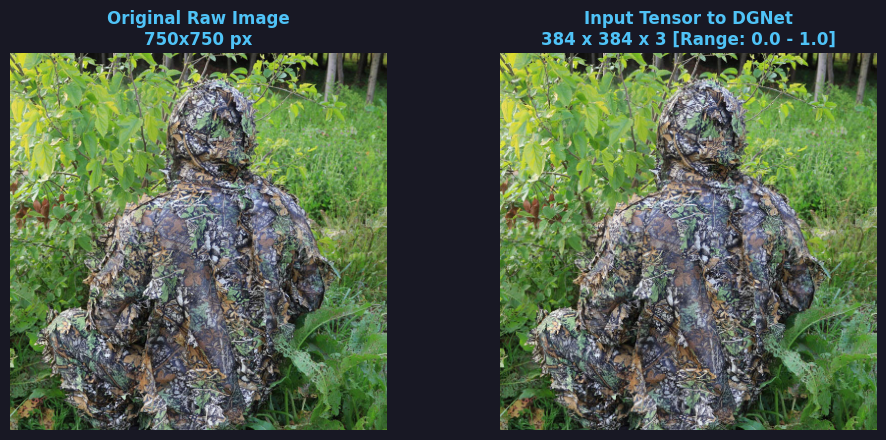

In [4]:
def load_and_preprocess_image(image_path, target_size=(384, 384)):
    """Load an image from disk, convert to RGB, and resize for DGNet."""
    if not os.path.exists(image_path):
        raise FileNotFoundError(f"Image not found at {image_path}")
    
    bgr = cv2.imread(str(image_path))
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    original_h, original_w = rgb.shape[:2]
    
    resized = cv2.resize(rgb, target_size, interpolation=cv2.INTER_LINEAR)
    tensor = tf.convert_to_tensor(resized, dtype=tf.float32) / 255.0
    tensor = tf.expand_dims(tensor, axis=0) # [1, H, W, 3]
    return rgb, resized, tensor, (original_h, original_w)

# Path to test image
image_path = r"C:\Users\Acer\Desktop\COD_PROJECT\data\raw\dataset-splitM\Training\images\image16.jpg"
orig_img, resized_img, input_tensor, orig_shape = load_and_preprocess_image(image_path)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].imshow(orig_img)
axes[0].set_title(f"Original Raw Image\n{orig_shape[1]}x{orig_shape[0]} px", fontsize=12, fontweight='bold', color='#4fc3f7')
axes[0].axis("off")

axes[1].imshow(resized_img)
axes[1].set_title("Input Tensor to DGNet\n384 x 384 x 3 [Range: 0.0 - 1.0]", fontsize=12, fontweight='bold', color='#4fc3f7')
axes[1].axis("off")

plt.tight_layout()
plt.show()


## 4. Feature Map Visualization Helper Utilities
In deep neural networks, intermediate feature maps have dozens or hundreds of channels (e.g., 32, 64, 160).
To visualize them meaningfully, we provide:
1. **Mean Activation Heatmap**: Spatial distribution of feature intensity across all channels.
2. **Channel Grid (Slices)**: Individual channel activations revealing specific edge detectors, frequency bands, and spatial patterns.
3. **RGB Overlay**: Blending activation heatmaps directly onto the input image for clear visual grounding.


In [5]:
def to_numpy_map(tensor):
    """Convert tensor [1, H, W, C] to 2D mean activation [H, W]."""
    arr = tensor.numpy() if hasattr(tensor, 'numpy') else tensor
    if arr.ndim == 4:
        arr = arr[0]
    if arr.ndim == 3:
        if arr.shape[-1] == 1:
            mean_map = arr[..., 0]
        else:
            mean_map = np.mean(arr, axis=-1)
    else:
        mean_map = arr
    # Normalize to [0, 1] for visualization
    denom = (mean_map.max() - mean_map.min() + 1e-8)
    return (mean_map - mean_map.min()) / denom

def plot_block_summary(tensor, block_name, role_description, colormap='inferno', overlay_bg=None):
    """Visualize mean activation heatmap, overlay, and statistics for a block output."""
    act_map = to_numpy_map(tensor)
    shape_str = f"{tensor.shape[1]}x{tensor.shape[2]}x{tensor.shape[3]}"
    
    ncols = 3 if overlay_bg is not None else 2
    fig, axes = plt.subplots(1, ncols, figsize=(4.5 * ncols, 4))
    
    # 1. Feature Heatmap
    im1 = axes[0].imshow(act_map, cmap=colormap)
    axes[0].set_title(f"{block_name}\nMean Activation [{shape_str}]", fontsize=11, fontweight='bold', color='#64ffda')
    axes[0].axis('off')
    plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)
    
    # 2. Histogram of Activations
    raw_vals = tensor.numpy().flatten()
    axes[1].hist(raw_vals, bins=40, color='#80d8ff', alpha=0.8, edgecolor='#0091ea')
    axes[1].set_title("Activation Distribution", fontsize=11, fontweight='bold', color='#80d8ff')
    axes[1].set_xlabel("Value")
    axes[1].set_ylabel("Count")
    axes[1].grid(alpha=0.2, linestyle='--')
    
    # 3. Optional Overlay
    if overlay_bg is not None:
        resized_map = cv2.resize(act_map, (overlay_bg.shape[1], overlay_bg.shape[0]), interpolation=cv2.INTER_LINEAR)
        colored_map = cm.get_cmap(colormap)(resized_map)[..., :3]
        blend = 0.55 * (overlay_bg / 255.0) + 0.45 * colored_map
        axes[2].imshow(np.clip(blend, 0, 1))
        axes[2].set_title("Overlay on Input", fontsize=11, fontweight='bold', color='#ffb74d')
        axes[2].axis('off')
        
    plt.suptitle(f"Block: {block_name} — {role_description}", fontsize=13, fontweight='bold', y=1.03, color='#ffffff')
    plt.tight_layout()
    plt.show()

def plot_channel_grid(tensor, block_name, num_channels=8, colormap='viridis'):
    """Show individual channel feature maps in a neat grid."""
    arr = tensor.numpy()[0]
    total_c = arr.shape[-1]
    num_to_show = min(num_channels, total_c)
    
    cols = 4
    rows = (num_to_show + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 2.8 * rows))
    axes = np.array(axes).reshape(-1)
    
    for i in range(len(axes)):
        if i < num_to_show:
            ch_data = arr[..., i]
            ch_norm = (ch_data - ch_data.min()) / (ch_data.max() - ch_data.min() + 1e-8)
            im = axes[i].imshow(ch_norm, cmap=colormap)
            axes[i].set_title(f"Channel #{i}", fontsize=9, color='#bbbbbb')
        axes[i].axis('off')
        
    plt.suptitle(f"{block_name}: Individual Channel Slices (Showing {num_to_show}/{total_c})", 
                 fontsize=12, fontweight='bold', y=1.02, color='#64ffda')
    plt.tight_layout()
    plt.show()


## 5. Stream 1: Texture / Gradient Encoder
**Architectural Role**:
The Texture Encoder extracts fine-grained edge and surface texture cues directly from the RGB image through 3 successive convolutional stages with stride 2:
1. `conv1`: $384 \times 384 \to 192 \times 192 \times 64$ ($7 \times 7$ kernel, stride 2)
2. `conv2`: $192 \times 192 \to 96 \times 96 \times 64$ ($3 \times 3$ kernel, stride 2)
3. `conv3`: $96 \times 96 \to 48 \times 48 \times 32$ ($3 \times 3$ kernel, stride 2) $\to$ produces **`xg: Gradient Features`**
4. `conv_out`: $48 \times 48 \times 32 \to 48 \times 48 \times 1$ ($1 \times 1$ kernel, stride 1) $\to$ produces **`pg: Edge Pred Logits`**


Stream 1: Texture / Gradient Encoder Outputs:
  • Stage 1 (conv1) : (1, 192, 192, 64) [H/2, W/2]
  • Stage 2 (conv2) : (1, 96, 96, 64) [H/4, W/4]
  • xg (Gradient Features) : (1, 48, 48, 32) [H/8, W/8, 32 channels]
  • pg (Edge Pred Logits) : (1, 48, 48, 1) [H/8, W/8, 1 channel]


C:\Users\Acer\AppData\Local\Temp\ipykernel_17596\605518272.py:42: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colored_map = cm.get_cmap(colormap)(resized_map)[..., :3]


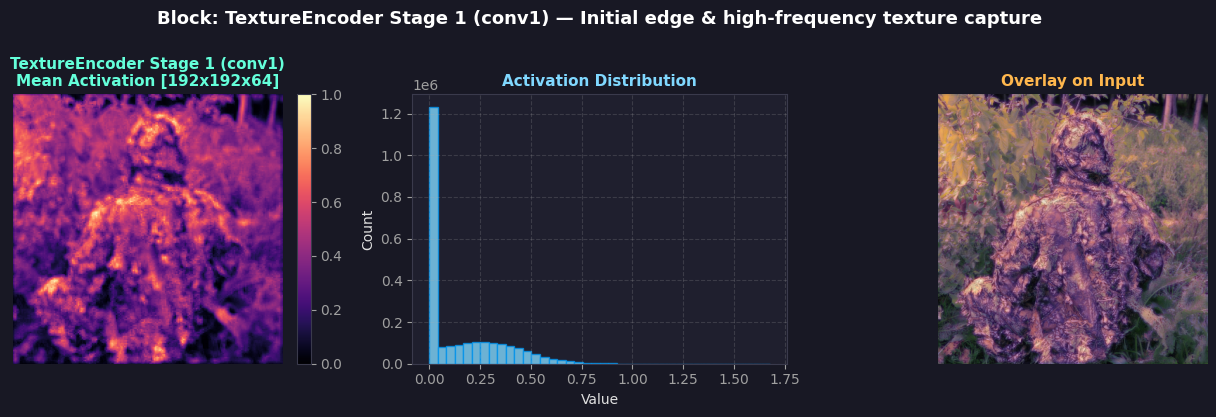

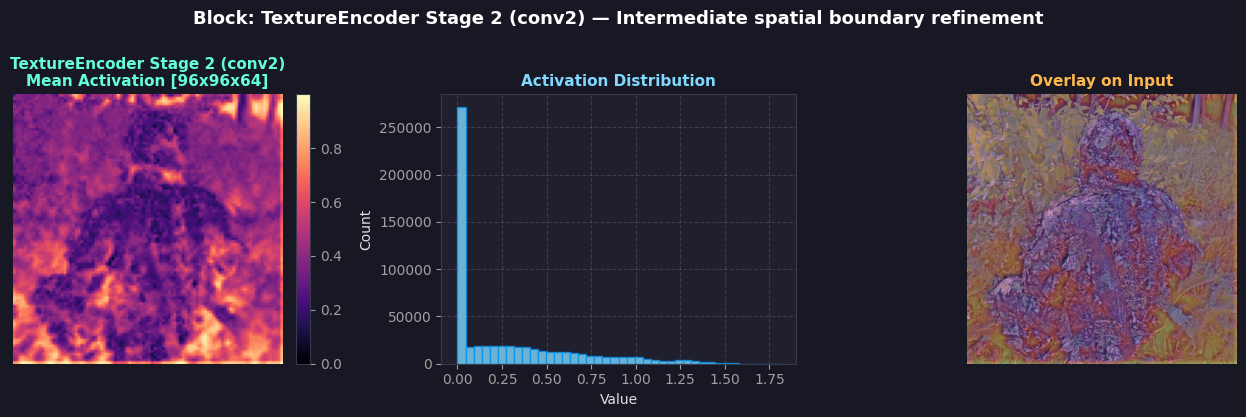

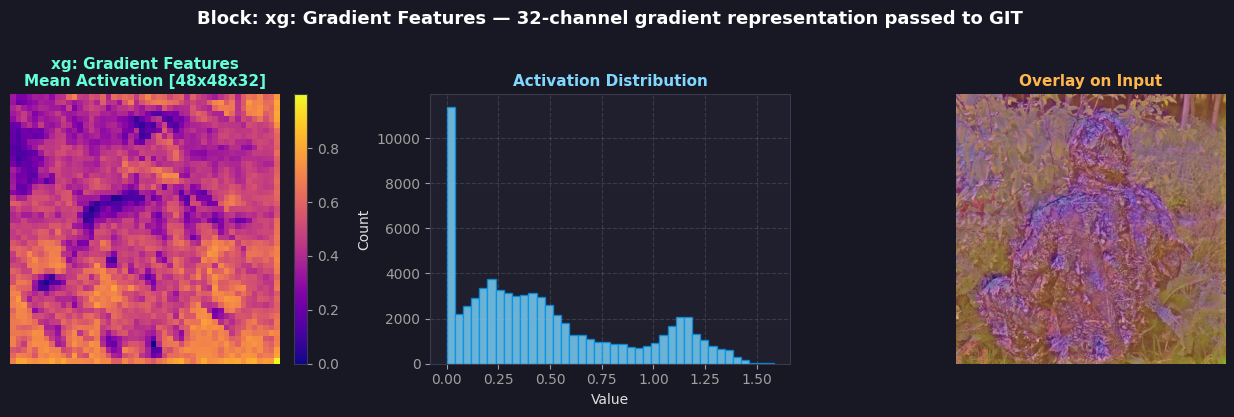

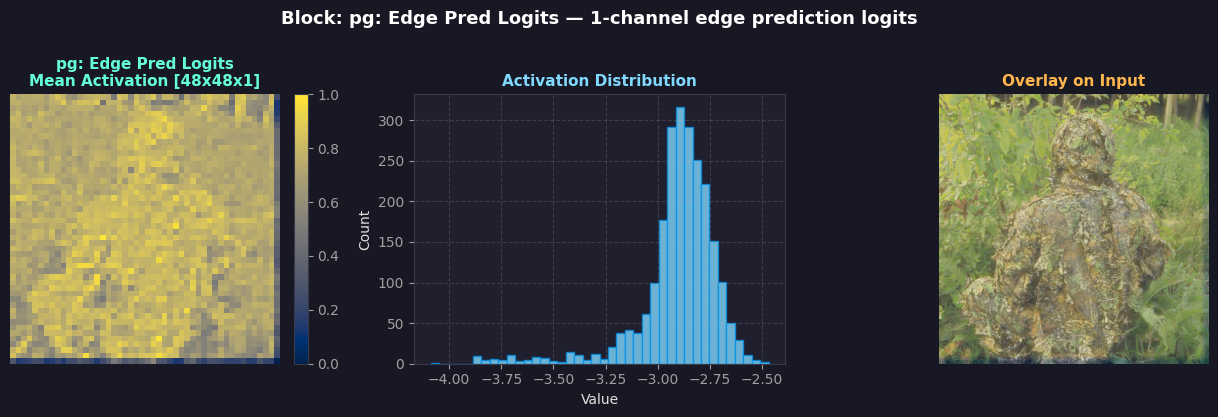

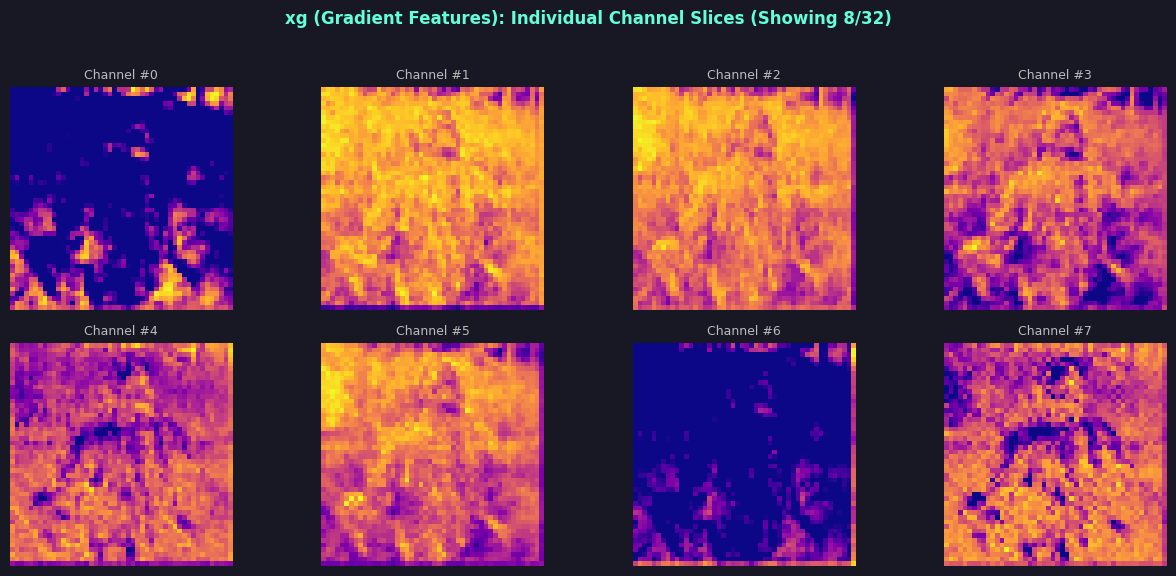

In [6]:
# Stream 1 Forward Execution
feat1 = model.texture_encoder.conv1(input_tensor, training=False)
feat2 = model.texture_encoder.conv2(feat1, training=False)
xg = model.texture_encoder.conv3(feat2, training=False)
pg = model.texture_encoder.conv_out(xg)

print("Stream 1: Texture / Gradient Encoder Outputs:")
print(f"  • Stage 1 (conv1) : {feat1.shape} [H/2, W/2]")
print(f"  • Stage 2 (conv2) : {feat2.shape} [H/4, W/4]")
print(f"  • xg (Gradient Features) : {xg.shape} [H/8, W/8, 32 channels]")
print(f"  • pg (Edge Pred Logits) : {pg.shape} [H/8, W/8, 1 channel]")

# Visualizations
plot_block_summary(feat1, "TextureEncoder Stage 1 (conv1)", "Initial edge & high-frequency texture capture", colormap="magma", overlay_bg=resized_img)
plot_block_summary(feat2, "TextureEncoder Stage 2 (conv2)", "Intermediate spatial boundary refinement", colormap="magma", overlay_bg=resized_img)
plot_block_summary(xg, "xg: Gradient Features", "32-channel gradient representation passed to GIT", colormap="plasma", overlay_bg=resized_img)
plot_block_summary(pg, "pg: Edge Pred Logits", "1-channel edge prediction logits", colormap="cividis", overlay_bg=resized_img)

# Individual channel slices of xg
plot_channel_grid(xg, "xg (Gradient Features)", num_channels=8, colormap="plasma")


## 6. Stream 2: Context Semantic Encoder (Backbone & DR + CBAM)
**Architectural Role**:
The Context Encoder extracts high-level semantic representation at 3 multi-scale strides:
- **`x3 (Stride 8)`**: $48 \times 48 \times C_3$ (fine context & spatial details)
- **`x4 (Stride 16)`**: $24 \times 24 \times C_4$ (mid-level semantic structures)
- **`x5 (Stride 32)`**: $12 \times 12 \times C_5$ (coarse high-level category & global context)

**Dimensional Reduction (DR) + CBAM Attention**:
Each raw backbone feature map has high channel dimensions (e.g. 40, 112, 160).
`DR3`, `DR4`, and `DR5` each use two ConvBR layers and a **CBAM Attention** block (Channel + Spatial attention) to compress the features down to a standardized **64 channels**:
- `x3` $\to$ `DR3 + CBAM` $\to$ **`xr3: (48 x 48 x 64)`**
- `x4` $\to$ `DR4 + CBAM` $\to$ **`xr4: (24 x 24 x 64)`**
- `x5` $\to$ `DR5 + CBAM` $\to$ **`xr5: (12 x 12 x 64)`**


Stream 2: Context Semantic Encoder Outputs:
  • Backbone x3 (Stride 8) : (1, 48, 48, 40)
  • Backbone x4 (Stride 16): (1, 24, 24, 112)
  • Backbone x5 (Stride 32): (1, 12, 12, 160)
  • xr3 (DR3 + CBAM Output): (1, 48, 48, 64)
  • xr4 (DR4 + CBAM Output): (1, 24, 24, 64)
  • xr5 (DR5 + CBAM Output): (1, 12, 12, 64)


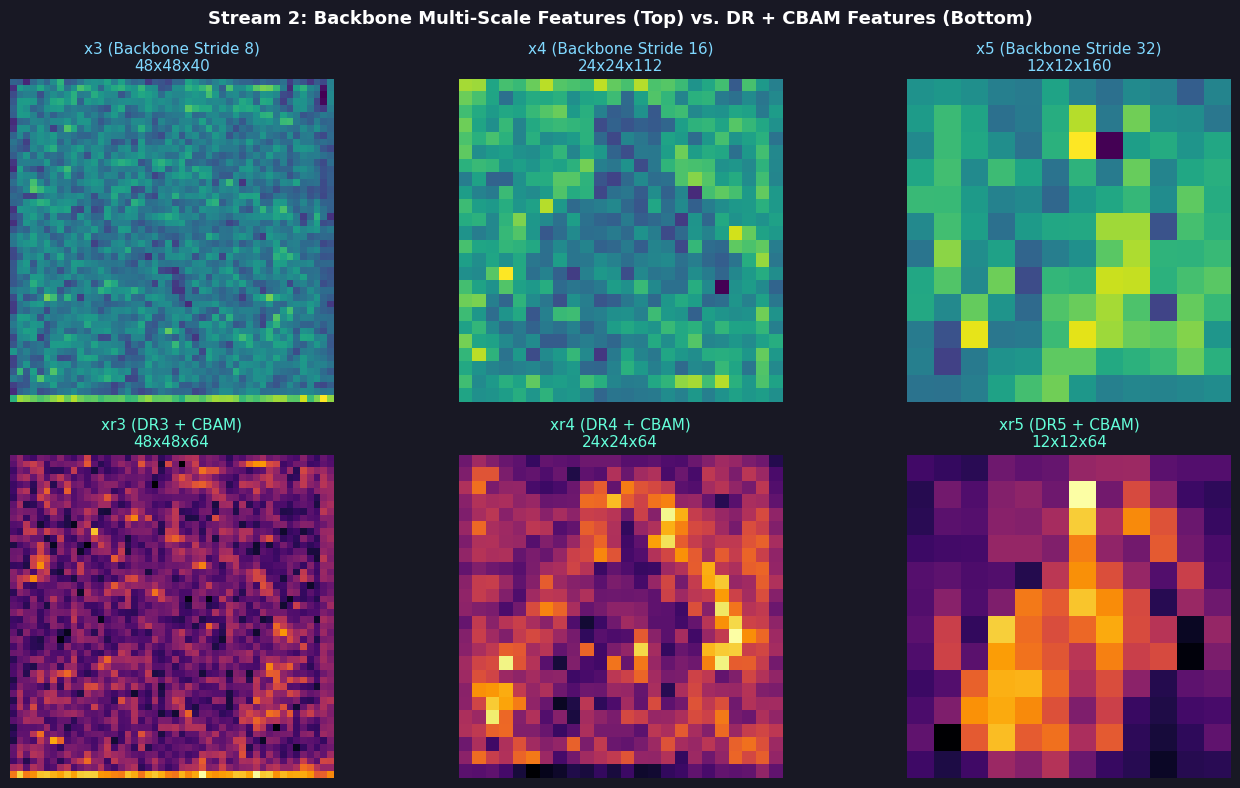

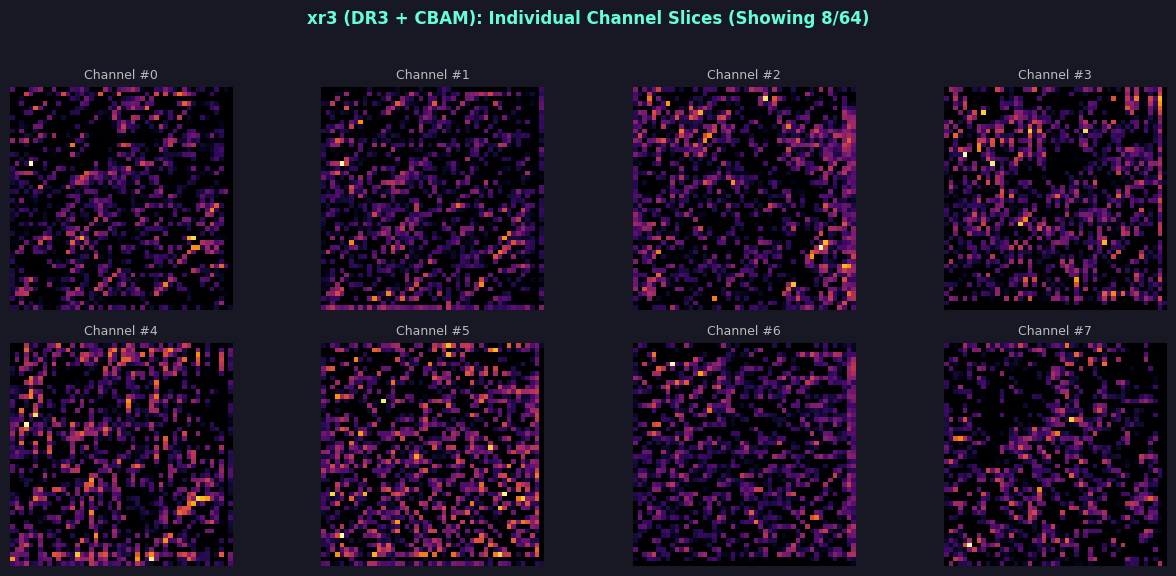

In [7]:
# Stream 2 Forward Execution
x3, x4, x5 = model.context_encoder(input_tensor, training=False)

xr3 = model.dr3(x3, training=False)
xr4 = model.dr4(x4, training=False)
xr5 = model.dr5(x5, training=False)

print("Stream 2: Context Semantic Encoder Outputs:")
print(f"  • Backbone x3 (Stride 8) : {x3.shape}")
print(f"  • Backbone x4 (Stride 16): {x4.shape}")
print(f"  • Backbone x5 (Stride 32): {x5.shape}")
print(f"  • xr3 (DR3 + CBAM Output): {xr3.shape}")
print(f"  • xr4 (DR4 + CBAM Output): {xr4.shape}")
print(f"  • xr5 (DR5 + CBAM Output): {xr5.shape}")

# Comparative visualization: Backbone features vs DR + CBAM features
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

# Row 1: Raw Backbone
axes[0, 0].imshow(to_numpy_map(x3), cmap='viridis')
axes[0, 0].set_title(f"x3 (Backbone Stride 8)\n{x3.shape[1]}x{x3.shape[2]}x{x3.shape[3]}", fontsize=11, color='#80d8ff')
axes[0, 0].axis('off')

axes[0, 1].imshow(to_numpy_map(x4), cmap='viridis')
axes[0, 1].set_title(f"x4 (Backbone Stride 16)\n{x4.shape[1]}x{x4.shape[2]}x{x4.shape[3]}", fontsize=11, color='#80d8ff')
axes[0, 1].axis('off')

axes[0, 2].imshow(to_numpy_map(x5), cmap='viridis')
axes[0, 2].set_title(f"x5 (Backbone Stride 32)\n{x5.shape[1]}x{x5.shape[2]}x{x5.shape[3]}", fontsize=11, color='#80d8ff')
axes[0, 2].axis('off')

# Row 2: Reduced + CBAM
axes[1, 0].imshow(to_numpy_map(xr3), cmap='inferno')
axes[1, 0].set_title(f"xr3 (DR3 + CBAM)\n{xr3.shape[1]}x{xr3.shape[2]}x{xr3.shape[3]}", fontsize=11, color='#64ffda')
axes[1, 0].axis('off')

axes[1, 1].imshow(to_numpy_map(xr4), cmap='inferno')
axes[1, 1].set_title(f"xr4 (DR4 + CBAM)\n{xr4.shape[1]}x{xr4.shape[2]}x{xr4.shape[3]}", fontsize=11, color='#64ffda')
axes[1, 1].axis('off')

axes[1, 2].imshow(to_numpy_map(xr5), cmap='inferno')
axes[1, 2].set_title(f"xr5 (DR5 + CBAM)\n{xr5.shape[1]}x{xr5.shape[2]}x{xr5.shape[3]}", fontsize=11, color='#64ffda')
axes[1, 2].axis('off')

plt.suptitle("Stream 2: Backbone Multi-Scale Features (Top) vs. DR + CBAM Features (Bottom)", 
             fontsize=13, fontweight='bold', y=0.98, color='#ffffff')
plt.tight_layout()
plt.show()

# Show channel slices for xr3
plot_channel_grid(xr3, "xr3 (DR3 + CBAM)", num_channels=8, colormap='inferno')


## 7. Gradient-Induced Transition (GIT)
**Architectural Role**:
The GIT module is the core innovation of DGNet. It transfers gradient boundary cues from `xg` (Stream 1) into the semantic context features `xr3, xr4, xr5` (Stream 2):
1. **Downsample `xg`**:
   - `xg_down2`: downsampled to $24 \times 24$ to match `xr4`
   - `xg_down4`: downsampled to $12 \times 12$ to match `xr5`
2. **Feature Interleaving ($M=8$)**:
   - Interleaves $M=8$ channel chunks of `xr` (64 ch) and `xg` (32 ch) into $q$ ($96$ ch)
3. **Soft Grouping Strategy (SGS with $N=[4, 8, 16]$)**:
   - 3 parallel grouped $1 \times 1$ convolutions capture multi-frequency interactions
4. **Attention Residual Learning**:
   - $zt = xr + \text{SGS}(q)$
   - Outputs: **`zt3: (48 x 48 x 64)`**, **`zt4: (24 x 24 x 64)`**, **`zt5: (12 x 12 x 64)`**


Gradient-Induced Transition (GIT) Outputs:
  • Interleaved q3: (1, 48, 48, 96), q4: (1, 24, 24, 96), q5: (1, 12, 12, 96)
  • Transitioned zt3: (1, 48, 48, 64) [48x48x64]
  • Transitioned zt4: (1, 24, 24, 64) [24x24x64]
  • Transitioned zt5: (1, 12, 12, 64) [12x12x64]


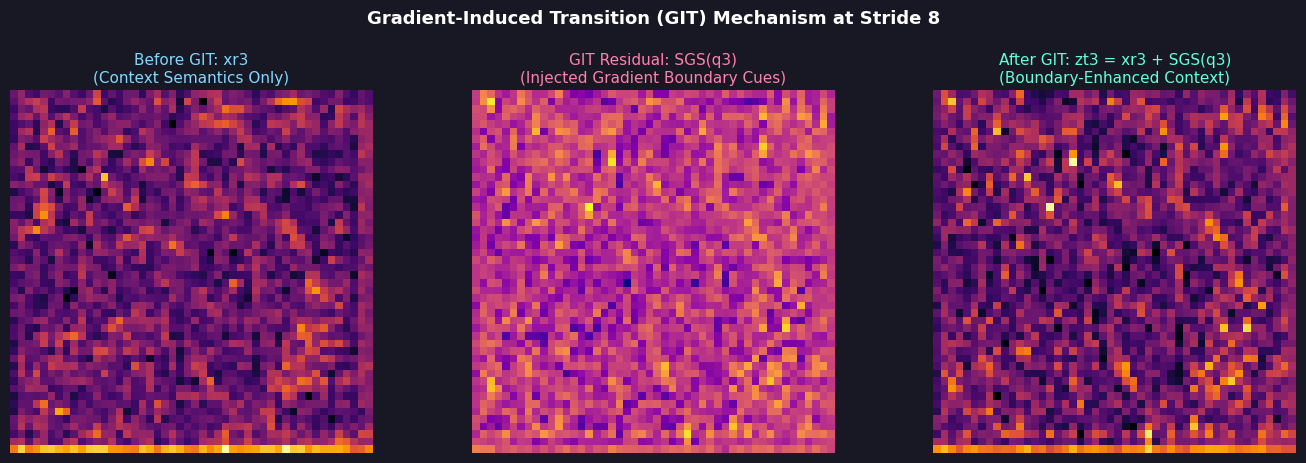

C:\Users\Acer\AppData\Local\Temp\ipykernel_17596\605518272.py:42: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colored_map = cm.get_cmap(colormap)(resized_map)[..., :3]


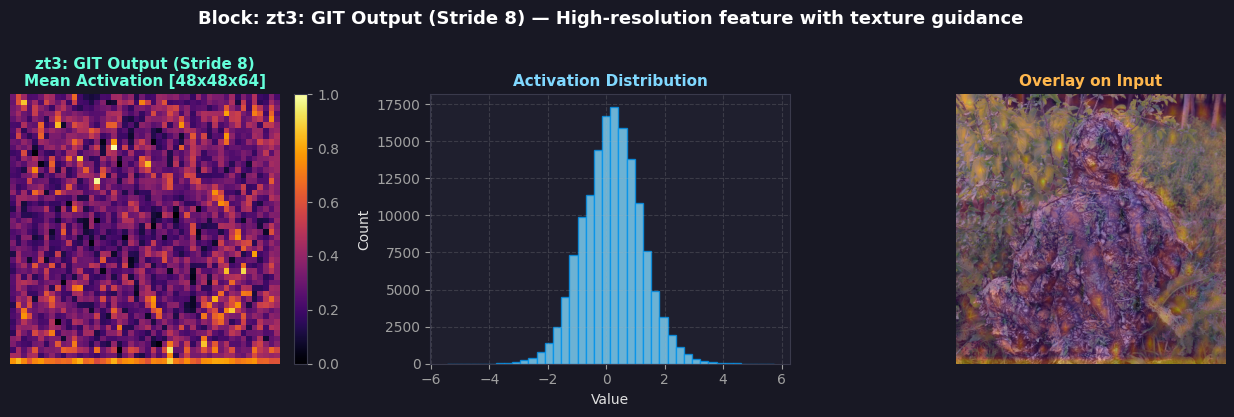

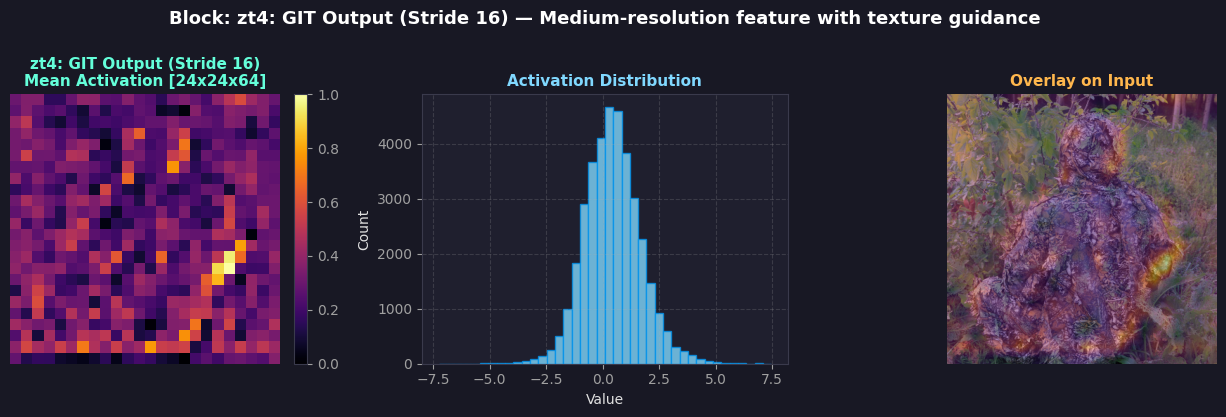

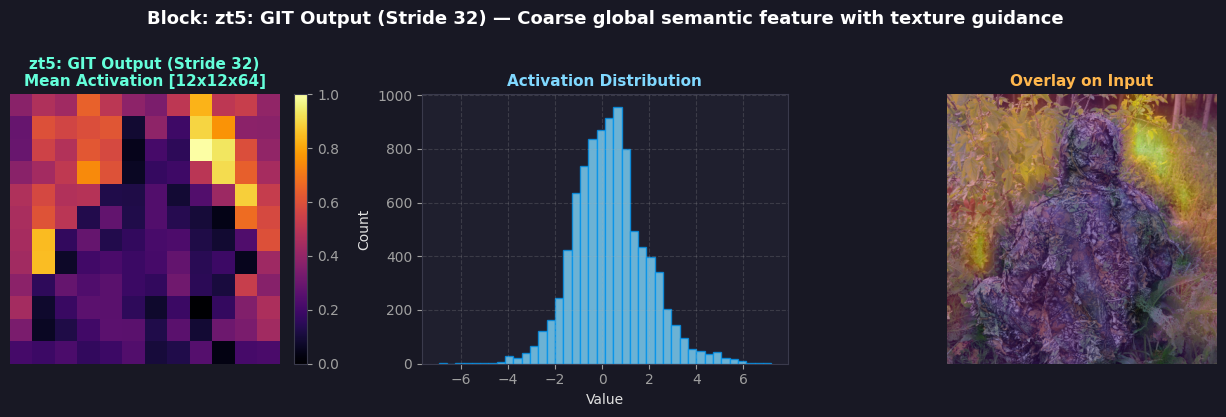

In [8]:
# Gradient-Induced Transition Execution
h4, w4 = tf.shape(xr4)[1], tf.shape(xr4)[2]
h5, w5 = tf.shape(xr5)[1], tf.shape(xr5)[2]

xg_down2 = tf.image.resize(xg, (h4, w4), method="bilinear")
xg_down4 = tf.image.resize(xg, (h5, w5), method="bilinear")

# Grouped feature interleaving
q3 = model.git._gradient_induced_feature_grouping(xr3, xg, M=model.git.M[0])
q4 = model.git._gradient_induced_feature_grouping(xr4, xg_down2, M=model.git.M[1])
q5 = model.git._gradient_induced_feature_grouping(xr5, xg_down4, M=model.git.M[2])

# Soft grouping + residual addition
delta_zt3 = model.git.sgs3(q3)
delta_zt4 = model.git.sgs4(q4)
delta_zt5 = model.git.sgs5(q5)

zt3 = xr3 + delta_zt3
zt4 = xr4 + delta_zt4
zt5 = xr5 + delta_zt5

print("Gradient-Induced Transition (GIT) Outputs:")
print(f"  • Interleaved q3: {q3.shape}, q4: {q4.shape}, q5: {q5.shape}")
print(f"  • Transitioned zt3: {zt3.shape} [48x48x64]")
print(f"  • Transitioned zt4: {zt4.shape} [24x24x64]")
print(f"  • Transitioned zt5: {zt5.shape} [12x12x64]")

# Visualizing GIT: Context before GIT (xr3) vs Gradient Delta vs Transitioned (zt3)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

axes[0].imshow(to_numpy_map(xr3), cmap='inferno')
axes[0].set_title("Before GIT: xr3\n(Context Semantics Only)", fontsize=11, color='#80d8ff')
axes[0].axis('off')

axes[1].imshow(to_numpy_map(delta_zt3), cmap='plasma')
axes[1].set_title("GIT Residual: SGS(q3)\n(Injected Gradient Boundary Cues)", fontsize=11, color='#ff80ab')
axes[1].axis('off')

axes[2].imshow(to_numpy_map(zt3), cmap='inferno')
axes[2].set_title("After GIT: zt3 = xr3 + SGS(q3)\n(Boundary-Enhanced Context)", fontsize=11, color='#64ffda')
axes[2].axis('off')

plt.suptitle("Gradient-Induced Transition (GIT) Mechanism at Stride 8", fontsize=13, fontweight='bold', y=1.02, color='#ffffff')
plt.tight_layout()
plt.show()

# Show zt3, zt4, zt5 side by side
plot_block_summary(zt3, "zt3: GIT Output (Stride 8)", "High-resolution feature with texture guidance", colormap="inferno", overlay_bg=resized_img)
plot_block_summary(zt4, "zt4: GIT Output (Stride 16)", "Medium-resolution feature with texture guidance", colormap="inferno", overlay_bg=resized_img)
plot_block_summary(zt5, "zt5: GIT Output (Stride 32)", "Coarse global semantic feature with texture guidance", colormap="inferno", overlay_bg=resized_img)


## 8. Neighbor Connection Decoder (NCD)
**Architectural Role**:
The Neighbor Connection Decoder fuses multi-scale features hierarchically from coarse to fine:
- **`zt5_1`**: Direct coarse base ($12 \times 12 \times 64$)
- **`zt4_1`**: Multiplicative fusion with upsampled `zt5`:
  $$\text{zt4\_1} = \text{ConvBR}(\text{Resize}(\text{zt5})) \odot \text{zt4} \quad (24 \times 24 \times 64)$$
- **`zt3_1`**: Multiplicative fusion with upsampled `zt4_1` & `zt4`:
  $$\text{zt3\_1} = \text{ConvBR}(\text{Resize}(\text{zt4\_1})) \odot \text{ConvBR}(\text{Resize}(\text{zt4})) \odot \text{zt3} \quad (48 \times 48 \times 64)$$
- **`zt4_2` & `zt3_2`**: Cross-scale concatenation and convolution projection
- **Prediction Heads**:
  - `pc5`: Aux Stride 32 Logits ($12 \times 12 \times 1$)
  - `pc4`: Aux Stride 16 Logits ($24 \times 24 \times 1$)
  - `pc`: Camouflage Logits ($48 \times 48 \times 1$)


Neighbor Connection Decoder (NCD) Outputs:
  • Fused zt4_1: (1, 24, 24, 64)
  • Fused zt3_1: (1, 48, 48, 64)
  • Concat zt4_2: (1, 24, 24, 64)
  • Concat zt3_2: (1, 48, 48, 64)
  • pc5 (Aux Stride 32 Logits): (1, 12, 12, 1)
  • pc4 (Aux Stride 16 Logits): (1, 24, 24, 1)
  • pc  (Camouflage Logits)   : (1, 48, 48, 1)


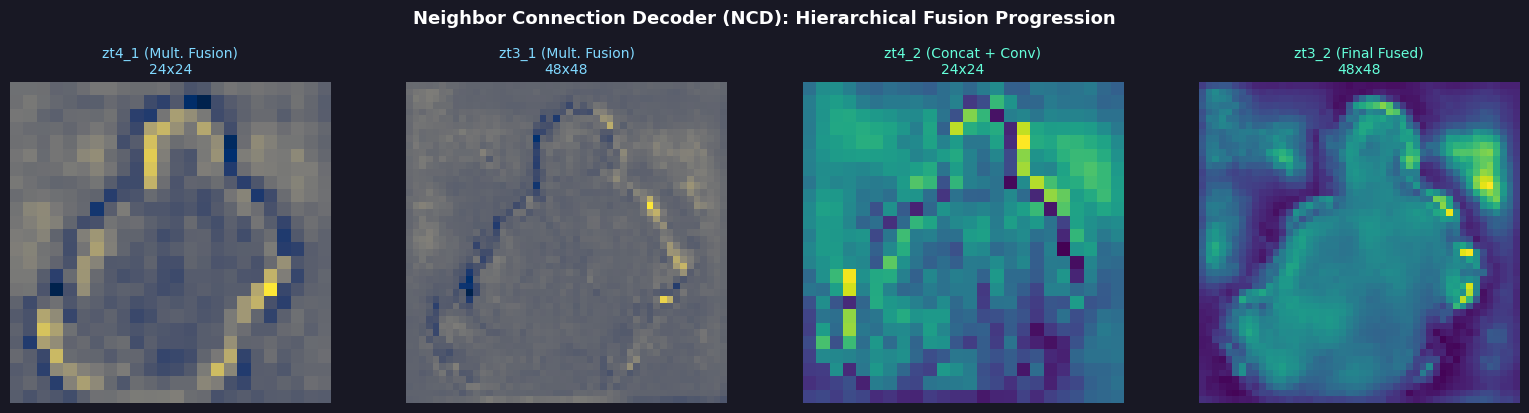

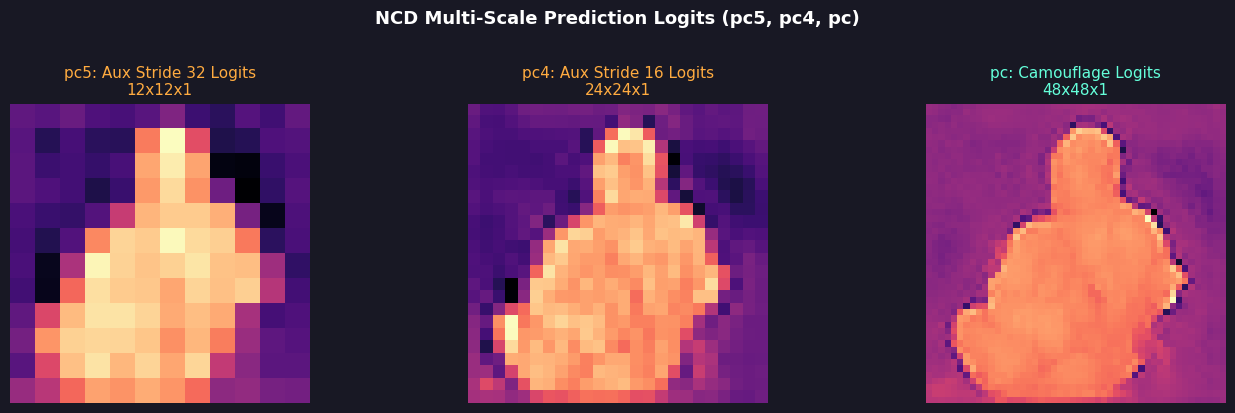

In [9]:
# Decoder Step-by-Step Execution
def resize_to(x, target):
    h, w = tf.shape(target)[1], tf.shape(target)[2]
    return tf.image.resize(x, (h, w), method="bilinear")

zt5_1 = zt5
zt4_1 = model.ncd.conv_upsample1(resize_to(zt5, zt4), training=False) * zt4
zt3_1 = (
    model.ncd.conv_upsample2(resize_to(zt4_1, zt3), training=False) *
    model.ncd.conv_upsample3(resize_to(zt4, zt3), training=False) *
    zt3
)

zt4_2 = tf.concat([zt4_1, model.ncd.conv_upsample4(resize_to(zt5_1, zt4), training=False)], axis=-1)
zt4_2 = model.ncd.conv_concat2(zt4_2, training=False)

zt3_2 = tf.concat([zt3_1, model.ncd.conv_upsample5(resize_to(zt4_2, zt3), training=False)], axis=-1)
zt3_2 = model.ncd.conv_concat3(zt3_2, training=False)

# Heads
pc = model.ncd.conv4(zt3_2, training=False)
pc = model.ncd.conv5(pc)

pc4 = model.ncd.aux_conv4(zt4_2)
pc5 = model.ncd.aux_conv5(zt5_1)

print("Neighbor Connection Decoder (NCD) Outputs:")
print(f"  • Fused zt4_1: {zt4_1.shape}")
print(f"  • Fused zt3_1: {zt3_1.shape}")
print(f"  • Concat zt4_2: {zt4_2.shape}")
print(f"  • Concat zt3_2: {zt3_2.shape}")
print(f"  • pc5 (Aux Stride 32 Logits): {pc5.shape}")
print(f"  • pc4 (Aux Stride 16 Logits): {pc4.shape}")
print(f"  • pc  (Camouflage Logits)   : {pc.shape}")

# Visualizing NCD Fusion Stages
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(to_numpy_map(zt4_1), cmap='cividis')
axes[0].set_title(f"zt4_1 (Mult. Fusion)\n{zt4_1.shape[1]}x{zt4_1.shape[2]}", fontsize=10, color='#80d8ff')
axes[0].axis('off')

axes[1].imshow(to_numpy_map(zt3_1), cmap='cividis')
axes[1].set_title(f"zt3_1 (Mult. Fusion)\n{zt3_1.shape[1]}x{zt3_1.shape[2]}", fontsize=10, color='#80d8ff')
axes[1].axis('off')

axes[2].imshow(to_numpy_map(zt4_2), cmap='viridis')
axes[2].set_title(f"zt4_2 (Concat + Conv)\n{zt4_2.shape[1]}x{zt4_2.shape[2]}", fontsize=10, color='#64ffda')
axes[2].axis('off')

axes[3].imshow(to_numpy_map(zt3_2), cmap='viridis')
axes[3].set_title(f"zt3_2 (Final Fused)\n{zt3_2.shape[1]}x{zt3_2.shape[2]}", fontsize=10, color='#64ffda')
axes[3].axis('off')

plt.suptitle("Neighbor Connection Decoder (NCD): Hierarchical Fusion Progression", fontsize=13, fontweight='bold', y=1.02, color='#ffffff')
plt.tight_layout()
plt.show()

# Show the 3 prediction logits
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(to_numpy_map(pc5), cmap='magma')
axes[0].set_title(f"pc5: Aux Stride 32 Logits\n{pc5.shape[1]}x{pc5.shape[2]}x1", fontsize=11, color='#ffab40')
axes[0].axis('off')

axes[1].imshow(to_numpy_map(pc4), cmap='magma')
axes[1].set_title(f"pc4: Aux Stride 16 Logits\n{pc4.shape[1]}x{pc4.shape[2]}x1", fontsize=11, color='#ffab40')
axes[1].axis('off')

axes[2].imshow(to_numpy_map(pc), cmap='magma')
axes[2].set_title(f"pc: Camouflage Logits\n{pc.shape[1]}x{pc.shape[2]}x1", fontsize=11, color='#64ffda')
axes[2].axis('off')

plt.suptitle("NCD Multi-Scale Prediction Logits (pc5, pc4, pc)", fontsize=13, fontweight='bold', y=1.02, color='#ffffff')
plt.tight_layout()
plt.show()


## 9. Full-Resolution Outputs (384 x 384)
**Architectural Role**:
All prediction heads (`pg`, `pc5`, `pc4`, `pc`) are bilinearly upsampled to the full image resolution ($384 \times 384$) and passed through the $\text{Sigmoid}$ activation function to yield normalized probability maps $[0, 1]$:
1. **Predicted Edge Map**: $\sigma(\text{Bilinear}(pg))$
2. **Auxiliary Stride 32 Mask**: $\sigma(\text{Bilinear}(pc5))$
3. **Auxiliary Stride 16 Mask**: $\sigma(\text{Bilinear}(pc4))$
4. **Final Camouflage Mask**: $\sigma(\text{Bilinear}(pc))$


Full-Resolution Output Maps (384 x 384):
  • Predicted Edge Map   : (384, 384) [Min: 0.016, Max: 0.076]
  • Aux Stride 32 Mask   : (384, 384) [Min: 0.000, Max: 0.999]
  • Aux Stride 16 Mask   : (384, 384) [Min: 0.000, Max: 1.000]
  • Final Camouflage Mask: (384, 384) [Min: 0.000, Max: 1.000]


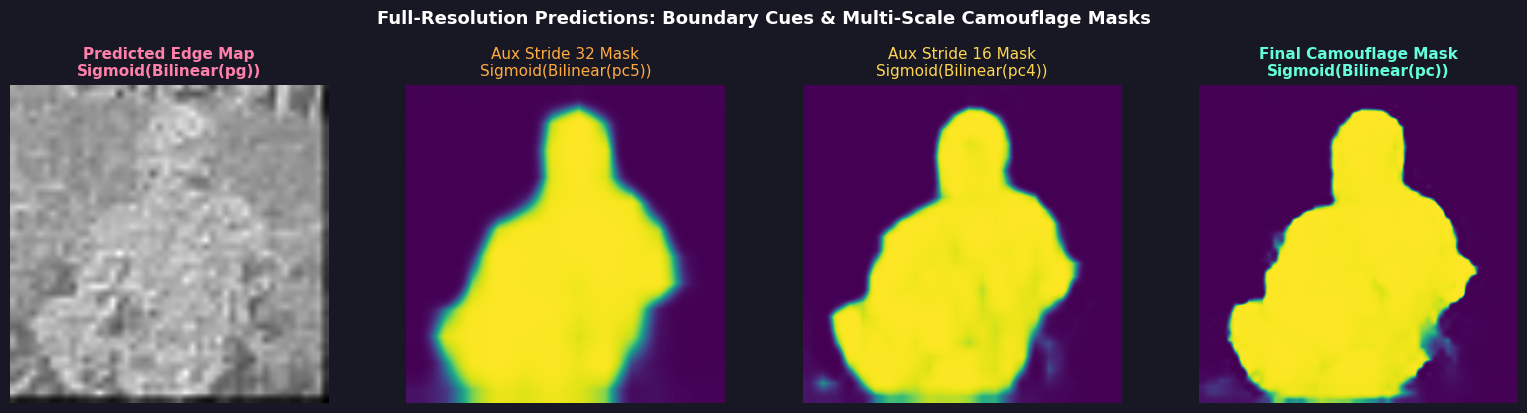

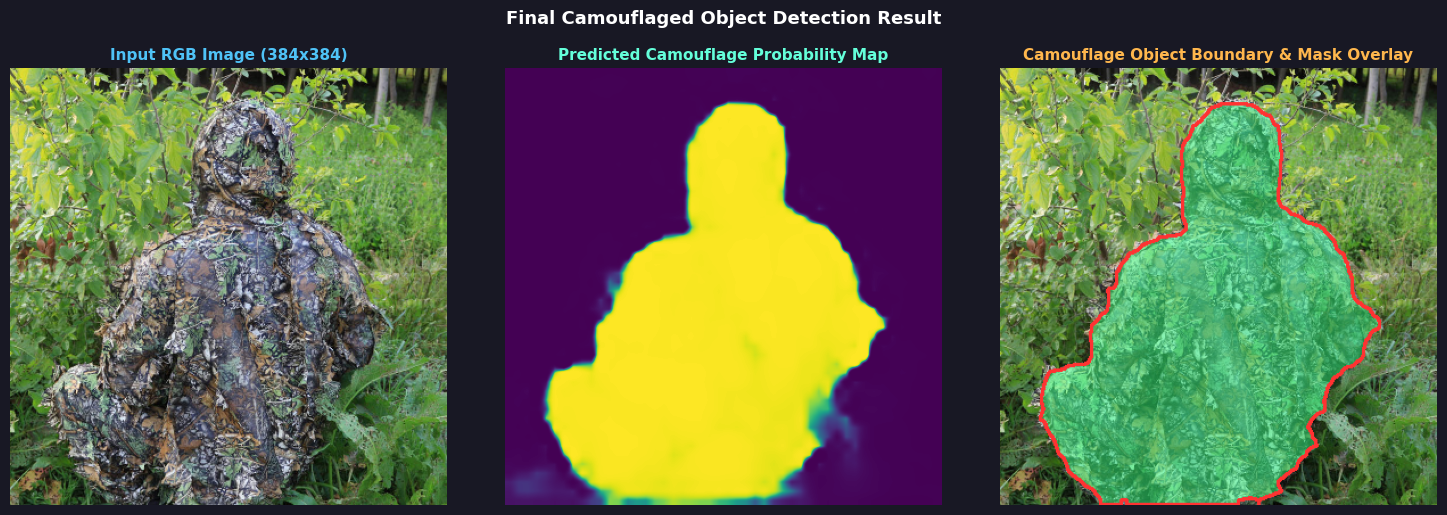

In [10]:
target_h, target_w = 384, 384

# Full-resolution bilinear interpolation + sigmoid
edge_map = tf.nn.sigmoid(tf.image.resize(pg, (target_h, target_w), method="bilinear")).numpy()[0, ..., 0]
aux5_map = tf.nn.sigmoid(tf.image.resize(pc5, (target_h, target_w), method="bilinear")).numpy()[0, ..., 0]
aux4_map = tf.nn.sigmoid(tf.image.resize(pc4, (target_h, target_w), method="bilinear")).numpy()[0, ..., 0]
final_mask = tf.nn.sigmoid(tf.image.resize(pc, (target_h, target_w), method="bilinear")).numpy()[0, ..., 0]

print("Full-Resolution Output Maps (384 x 384):")
print(f"  • Predicted Edge Map   : {edge_map.shape} [Min: {edge_map.min():.3f}, Max: {edge_map.max():.3f}]")
print(f"  • Aux Stride 32 Mask   : {aux5_map.shape} [Min: {aux5_map.min():.3f}, Max: {aux5_map.max():.3f}]")
print(f"  • Aux Stride 16 Mask   : {aux4_map.shape} [Min: {aux4_map.min():.3f}, Max: {aux4_map.max():.3f}]")
print(f"  • Final Camouflage Mask: {final_mask.shape} [Min: {final_mask.min():.3f}, Max: {final_mask.max():.3f}]")

# Visual Display of Progression
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(edge_map, cmap='gray')
axes[0].set_title("Predicted Edge Map\nSigmoid(Bilinear(pg))", fontsize=11, fontweight='bold', color='#ff80ab')
axes[0].axis('off')

axes[1].imshow(aux5_map, cmap='viridis')
axes[1].set_title("Aux Stride 32 Mask\nSigmoid(Bilinear(pc5))", fontsize=11, color='#ffab40')
axes[1].axis('off')

axes[2].imshow(aux4_map, cmap='viridis')
axes[2].set_title("Aux Stride 16 Mask\nSigmoid(Bilinear(pc4))", fontsize=11, color='#ffd54f')
axes[2].axis('off')

axes[3].imshow(final_mask, cmap='viridis')
axes[3].set_title("Final Camouflage Mask\nSigmoid(Bilinear(pc))", fontsize=11, fontweight='bold', color='#64ffda')
axes[3].axis('off')

plt.suptitle("Full-Resolution Predictions: Boundary Cues & Multi-Scale Camouflage Masks", fontsize=13, fontweight='bold', y=1.02, color='#ffffff')
plt.tight_layout()
plt.show()

# High-contrast Overlay on Input Image
binary_mask = (final_mask > 0.5).astype(np.uint8)
contours, _ = cv2.findContours(binary_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

overlay_img = resized_img.copy()
# Draw transparent green mask on detected regions
green_mask = np.zeros_like(overlay_img)
green_mask[binary_mask == 1] = [50, 255, 120]
overlay_blended = np.where(binary_mask[..., None] == 1, cv2.addWeighted(overlay_img, 0.5, green_mask, 0.5, 0), overlay_img)
cv2.drawContours(overlay_blended, contours, -1, (255, 50, 50), 2)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(resized_img)
axes[0].set_title("Input RGB Image (384x384)", fontsize=11, fontweight='bold', color='#4fc3f7')
axes[0].axis('off')

axes[1].imshow(final_mask, cmap='viridis')
axes[1].set_title("Predicted Camouflage Probability Map", fontsize=11, fontweight='bold', color='#64ffda')
axes[1].axis('off')

axes[2].imshow(overlay_blended)
axes[2].set_title("Camouflage Object Boundary & Mask Overlay", fontsize=11, fontweight='bold', color='#ffb74d')
axes[2].axis('off')

plt.suptitle("Final Camouflaged Object Detection Result", fontsize=13, fontweight='bold', y=1.02, color='#ffffff')
plt.tight_layout()
plt.show()


## 10. Master Architecture Flow Dashboard (All Blocks in One View)
Below is the complete gallery of every single named block from the DGNet architecture diagram, presented in topological sequence as the image flows through the network.


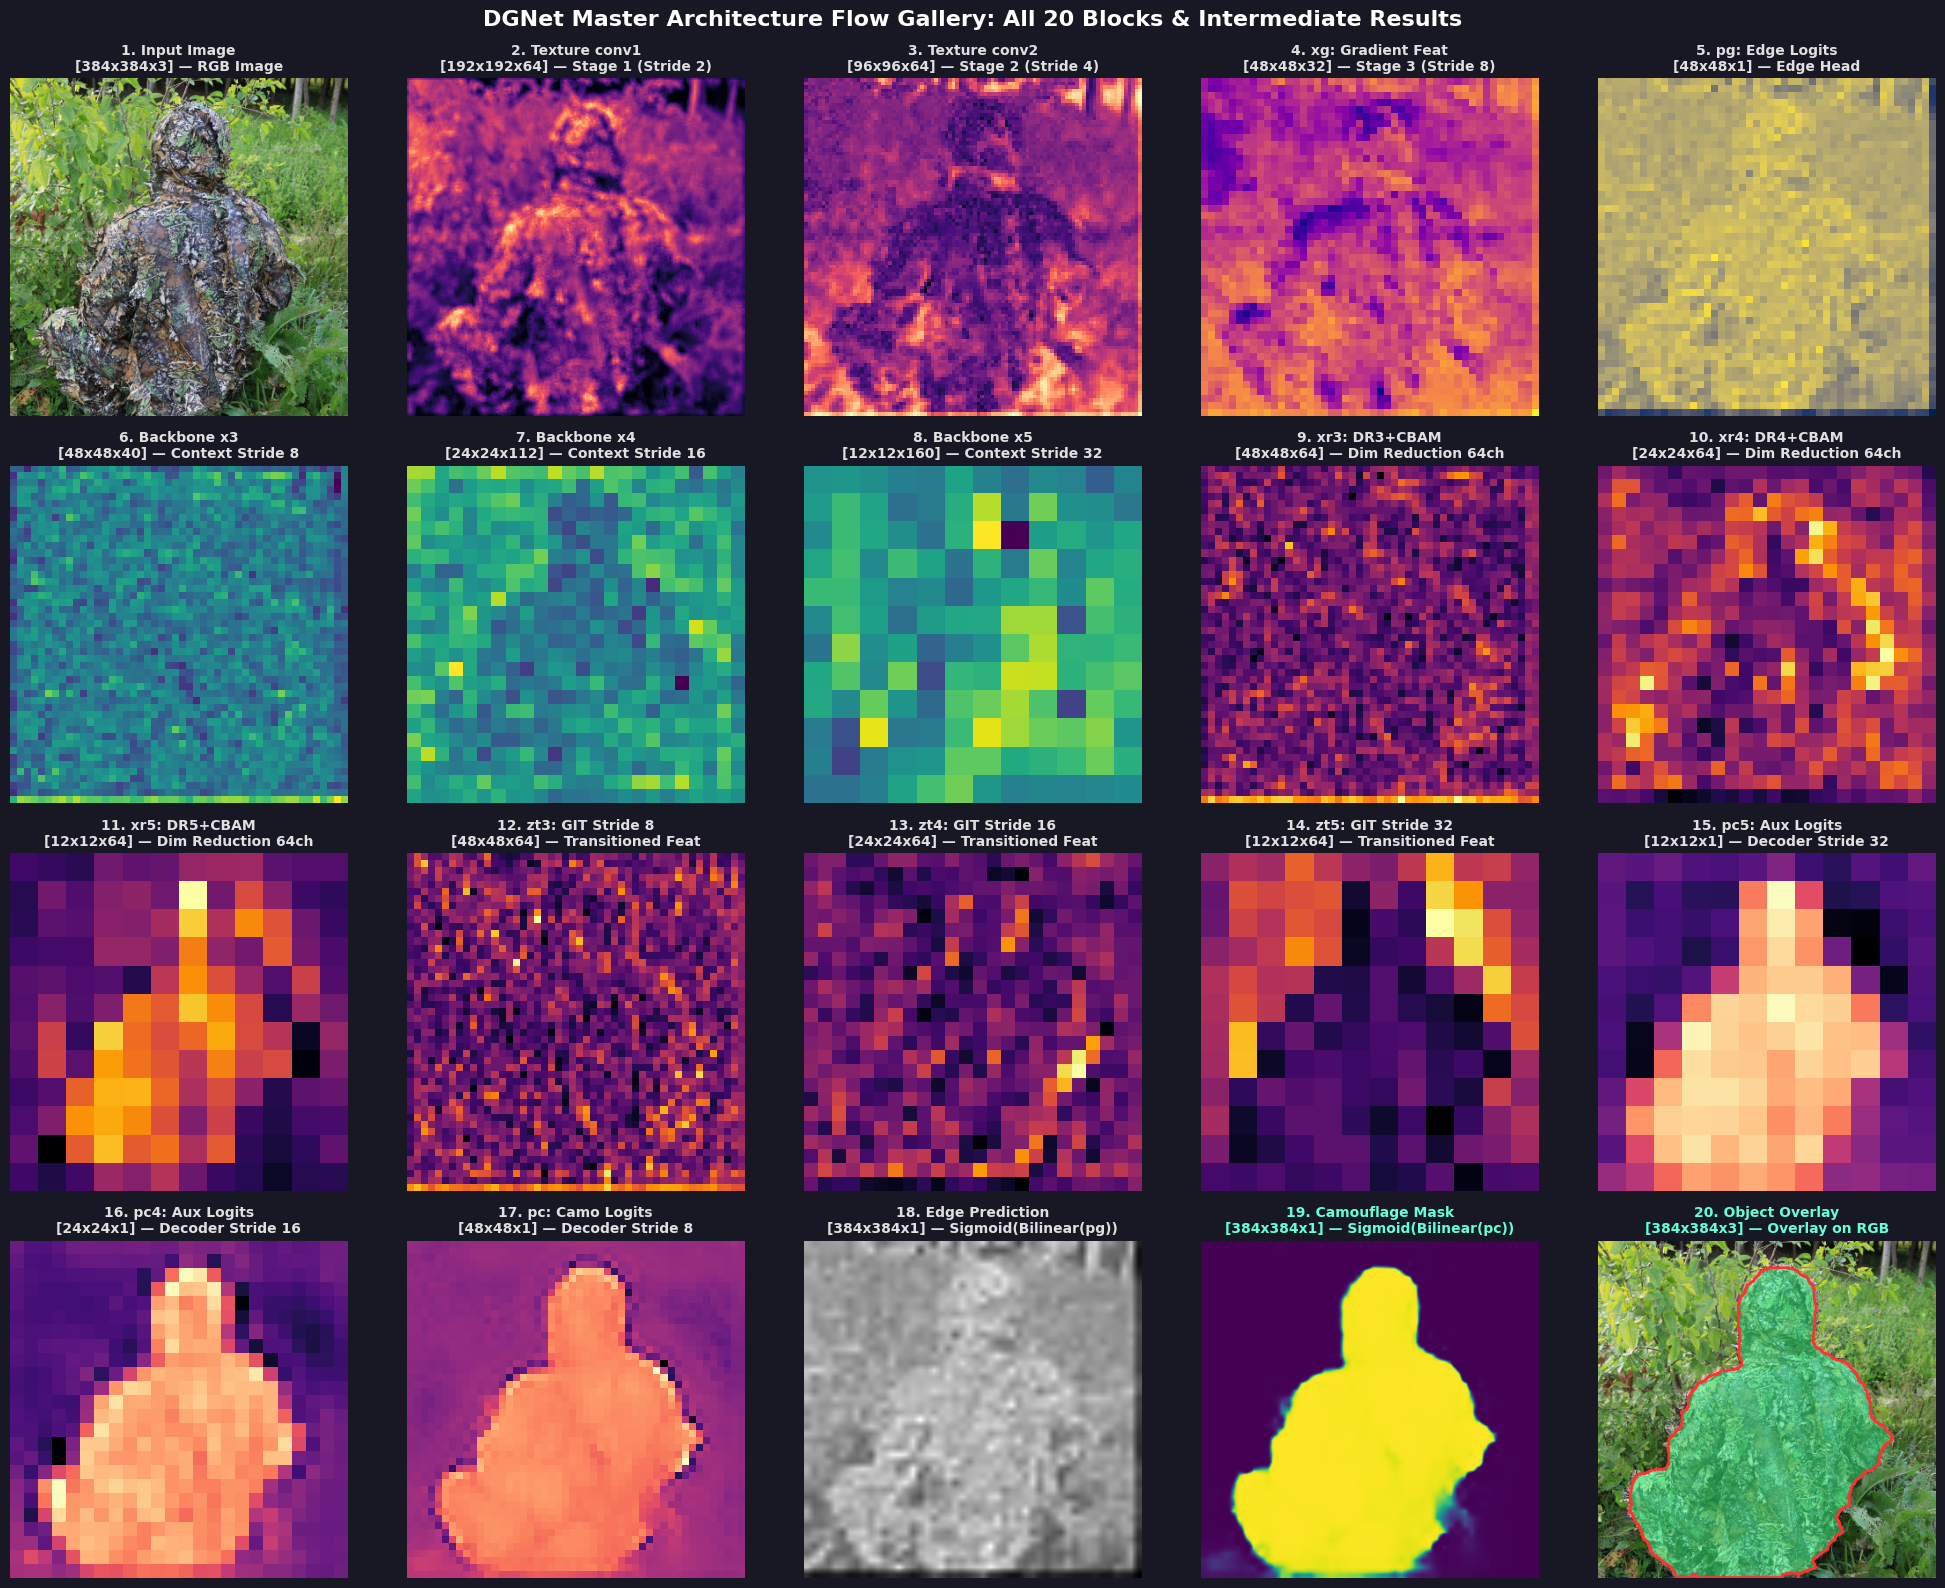

In [11]:
# Master Grid of All Blocks Named in the Diagram
blocks_to_show = [
    ("1. Input Image", resized_img, "RGB Image", "384x384x3", "rgb"),
    ("2. Texture conv1", to_numpy_map(feat1), "Stage 1 (Stride 2)", "192x192x64", "magma"),
    ("3. Texture conv2", to_numpy_map(feat2), "Stage 2 (Stride 4)", "96x96x64", "magma"),
    ("4. xg: Gradient Feat", to_numpy_map(xg), "Stage 3 (Stride 8)", "48x48x32", "plasma"),
    ("5. pg: Edge Logits", to_numpy_map(pg), "Edge Head", "48x48x1", "cividis"),
    ("6. Backbone x3", to_numpy_map(x3), "Context Stride 8", f"{x3.shape[1]}x{x3.shape[2]}x{x3.shape[3]}", "viridis"),
    ("7. Backbone x4", to_numpy_map(x4), "Context Stride 16", f"{x4.shape[1]}x{x4.shape[2]}x{x4.shape[3]}", "viridis"),
    ("8. Backbone x5", to_numpy_map(x5), "Context Stride 32", f"{x5.shape[1]}x{x5.shape[2]}x{x5.shape[3]}", "viridis"),
    ("9. xr3: DR3+CBAM", to_numpy_map(xr3), "Dim Reduction 64ch", "48x48x64", "inferno"),
    ("10. xr4: DR4+CBAM", to_numpy_map(xr4), "Dim Reduction 64ch", "24x24x64", "inferno"),
    ("11. xr5: DR5+CBAM", to_numpy_map(xr5), "Dim Reduction 64ch", "12x12x64", "inferno"),
    ("12. zt3: GIT Stride 8", to_numpy_map(zt3), "Transitioned Feat", "48x48x64", "inferno"),
    ("13. zt4: GIT Stride 16", to_numpy_map(zt4), "Transitioned Feat", "24x24x64", "inferno"),
    ("14. zt5: GIT Stride 32", to_numpy_map(zt5), "Transitioned Feat", "12x12x64", "inferno"),
    ("15. pc5: Aux Logits", to_numpy_map(pc5), "Decoder Stride 32", "12x12x1", "magma"),
    ("16. pc4: Aux Logits", to_numpy_map(pc4), "Decoder Stride 16", "24x24x1", "magma"),
    ("17. pc: Camo Logits", to_numpy_map(pc), "Decoder Stride 8", "48x48x1", "magma"),
    ("18. Edge Prediction", edge_map, "Sigmoid(Bilinear(pg))", "384x384x1", "gray"),
    ("19. Camouflage Mask", final_mask, "Sigmoid(Bilinear(pc))", "384x384x1", "viridis"),
    ("20. Object Overlay", overlay_blended, "Overlay on RGB", "384x384x3", "rgb"),
]

fig, axes = plt.subplots(4, 5, figsize=(20, 16))
axes = axes.flatten()

for idx, (title, img_data, role, shape_str, cmap_name) in enumerate(blocks_to_show):
    ax = axes[idx]
    if cmap_name == "rgb":
        ax.imshow(img_data)
    else:
        ax.imshow(img_data, cmap=cmap_name)
    ax.set_title(f"{title}\n[{shape_str}] — {role}", fontsize=10, fontweight='bold', color='#64ffda' if '19' in title or '20' in title else '#e0e0e0')
    ax.axis('off')

plt.suptitle("DGNet Master Architecture Flow Gallery: All 20 Blocks & Intermediate Results", 
             fontsize=16, fontweight='bold', y=0.99, color='#ffffff')
plt.tight_layout()
plt.show()


## 11. Reusable Inspection Function for Any Image
Pass any image file path to `inspect_dgnet_blocks` to inspect the full architecture flow.


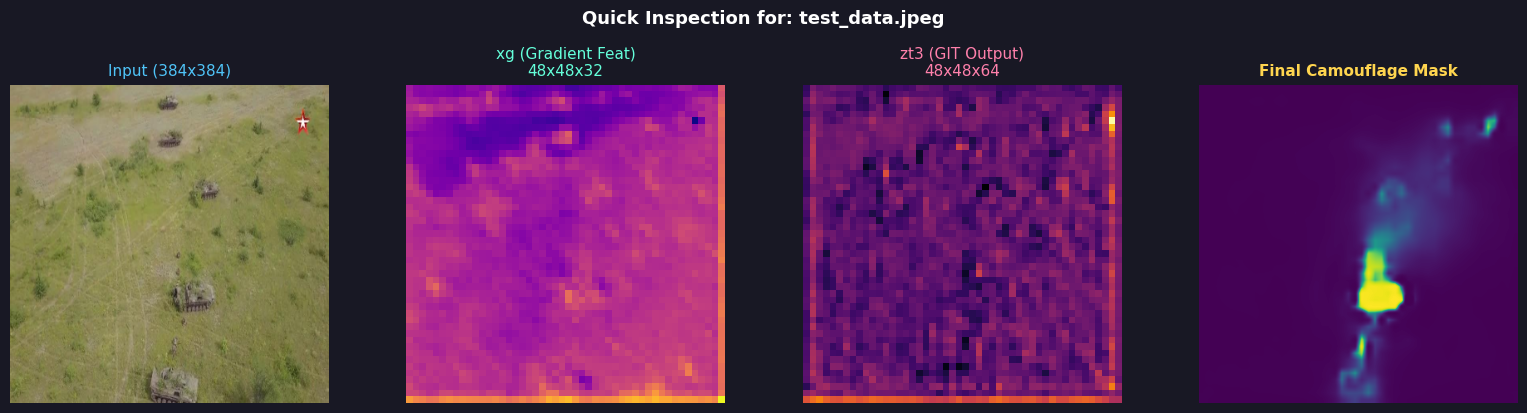

In [12]:
def inspect_dgnet_blocks(img_path, model_instance=model):
    """Pass any image path to run DGNet and display a complete block-by-block breakdown."""
    _, r_img, in_tensor, _ = load_and_preprocess_image(img_path)
    
    # 1. Texture
    f1 = model_instance.texture_encoder.conv1(in_tensor, training=False)
    f2 = model_instance.texture_encoder.conv2(f1, training=False)
    xg_f = model_instance.texture_encoder.conv3(f2, training=False)
    pg_f = model_instance.texture_encoder.conv_out(xg_f)
    
    # 2. Context
    bx3, bx4, bx5 = model_instance.context_encoder(in_tensor, training=False)
    rx3 = model_instance.dr3(bx3, training=False)
    rx4 = model_instance.dr4(bx4, training=False)
    rx5 = model_instance.dr5(bx5, training=False)
    
    # 3. GIT
    z3, z4, z5 = model_instance.git(rx3, rx4, rx5, xg_f, training=False)
    
    # 4. NCD
    p_c, p_c4, p_c5 = model_instance.ncd(z5, z4, z3, training=False)
    
    # 5. Full-resolution
    e_map = tf.nn.sigmoid(tf.image.resize(pg_f, (384, 384), method="bilinear")).numpy()[0, ..., 0]
    m_map = tf.nn.sigmoid(tf.image.resize(p_c, (384, 384), method="bilinear")).numpy()[0, ..., 0]
    
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    axes[0].imshow(r_img); axes[0].set_title("Input (384x384)", fontsize=11, color='#4fc3f7'); axes[0].axis('off')
    axes[1].imshow(to_numpy_map(xg_f), cmap='plasma'); axes[1].set_title(f"xg (Gradient Feat)\n{xg_f.shape[1]}x{xg_f.shape[2]}x32", fontsize=11, color='#64ffda'); axes[1].axis('off')
    axes[2].imshow(to_numpy_map(z3), cmap='inferno'); axes[2].set_title(f"zt3 (GIT Output)\n{z3.shape[1]}x{z3.shape[2]}x64", fontsize=11, color='#ff80ab'); axes[2].axis('off')
    axes[3].imshow(m_map, cmap='viridis'); axes[3].set_title("Final Camouflage Mask", fontsize=11, fontweight='bold', color='#ffd54f'); axes[3].axis('off')
    plt.suptitle(f"Quick Inspection for: {Path(img_path).name}", fontsize=13, fontweight='bold', y=1.02, color='#ffffff')
    plt.tight_layout()
    plt.show()

# Example test run on test_data.jpeg
inspect_dgnet_blocks(project_root / "test_data.jpeg")
